## 08 - Label validation

How reliable are the labels? I retrain the model with other seeds and compare its labels with my own blind coding of 196 reviews.

In [1]:
# --- IMPORTS ---
import os
import warnings

# Two warnings print a local path, so they are hidden before the imports that raise them:
# tqdm warns at import that ipywidgets is missing, and openpyxl warns when it reads the coding
# file, because Excel added an extension to the dropdown that openpyxl cannot read. The labels
# are read anyway.
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Data Validation extension is not supported")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from hdbscan import HDBSCAN
from openpyxl.styles import Alignment
from openpyxl.worksheet.datavalidation import DataValidation
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import cohen_kappa_score
from spacy.lang.it.stop_words import STOP_WORDS as italian_stopwords
from umap import UMAP

# UMAP seeds to train. 42 is the seed of 06, the others are compared with it.
UMAP_SEEDS = [42, 0, 1, 2, 3]
# Reviews drawn from each label (and from EXCLUDE) for the blind coding sample
SAMPLE_PER_LABEL = 14
# Fixed seed for the sample and its order, so the same sample comes out on every run
SAMPLE_SEED = 42
# The two coding files. labeling/ is in .gitignore, because the files contain review texts.
SAMPLE_PATH = "../labeling/validation_sample.xlsx"
KEY_PATH = "../labeling/validation_key.csv"

# Part 3: number of bootstrap resamples and their seed, so the intervals are the same on every run
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 42
# The disagreements file holds review texts too, so it also goes to labeling/
DISAGREEMENTS_PATH = "../labeling/validation_disagreements.csv"
CONFUSION_CHART_PATH = "../reports/figures/chart_label_confusion.png"

# 07 renamed some labels after the sample was drawn and coded. My coding and the key keep the
# names of that time, so they are mapped to the current names in code. The two station labels
# became one, Station Issues. Labels that are not listed here kept their name.
NEW_LABEL_NAMES = {
    "Unreliable Train Status": "Inaccurate Train Info",
    "Subscription Purchase Failures": "Subscription & Payment Failures",
    "App Crashes & Freezes": "App Not Working",
    "Station & Favorites Bugs": "Station Issues",
    "Missing Stations": "Station Issues",
    "Easy Purchase & Payment": "Easy Purchases",
    "Rail Service Complaints": "Train Service Complaints",
    "Version Comparisons": "Improvement Feedback",
}
# Station Issues joins the labels of two 06 topics. The topic number tells them apart again,
# to rebuild the strata the sample was drawn from.
STATION_STRATUM_BY_TOPIC = {7: "Station & Favorites Bugs", 28: "Missing Stations"}

W1112 18:27:07.576000 4356 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# --- LOAD DATA ---
# The cleaned reviews, with the same filter as 06: Italian reviews only
clean_df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")
italian_df = clean_df[clean_df["language"] == "it"].copy()

# The label of each review, saved by 07. It also keeps the topic number given by 06.
labeled_df = pd.read_csv("../data/processed/trenord_reviews_labeled.csv")

# The two files must list the same reviews in the same order, because the topics of the new
# runs are compared with the labels position by position.
same_reviews = italian_df["review_id"].tolist() == labeled_df["review_id"].tolist()
assert same_reviews, "The clean and labeled files do not list the same reviews in the same order"

print(f"Italian reviews : {len(italian_df):,}")
print(f"Labeled reviews : {len(labeled_df):,}")
print(f"Same reviews, same order: {same_reviews}")

Italian reviews : 6,951
Labeled reviews : 6,951
Same reviews, same order: True


In [3]:
# --- PREPARE TEXTS ---
# Same text column as 06: text_clean, in natural form for the embeddings.
# BERTopic cannot handle empty strings, so they are replaced by a single space, as in 06.
texts = italian_df["text_clean"].tolist()
for i in range(len(texts)):
    text = texts[i]
    is_valid = isinstance(text, str) and len(text.strip()) > 0
    if not is_valid:
        texts[i] = " "

print(f"Texts prepared: {len(texts):,}")

Texts prepared: 6,951


In [4]:
# --- SENTENCE EMBEDDINGS (computed once) ---
# Same model as 06. The embeddings do not depend on the UMAP seed, so they are computed
# once and passed to every run. 05 showed that this gives the same topics as 06.
embedding_model = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")
embeddings = embedding_model.encode(texts, show_progress_bar=False)

print(f"Embeddings: {embeddings.shape[0]} reviews x {embeddings.shape[1]} dimensions")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1210.24it/s]


Embeddings: 6951 reviews x 768 dimensions


In [5]:
# --- FUNCTION TO TRAIN THE MODEL OF 06 WITH A GIVEN UMAP SEED ---
def train_topic_model(umap_random_state):
    # Every setting is the same as in 06; only the UMAP seed changes.
    # Each run gets new model objects, because BERTopic fits them in place.
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine",
                      random_state=umap_random_state)
    hdbscan_model = HDBSCAN(min_cluster_size=30, metric="euclidean", prediction_data=True)
    vectorizer_model = CountVectorizer(stop_words=list(italian_stopwords), min_df=5, ngram_range=(1, 2))
    representation_model = MaximalMarginalRelevance(diversity=0.3)

    topic_model = BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        representation_model=representation_model,
        top_n_words=10,
        language="multilingual",
        calculate_probabilities=False,
        verbose=False
    )

    # Passing the embeddings skips the encoding step inside BERTopic
    topics_before, _ = topic_model.fit_transform(texts, embeddings=embeddings)

    # Outliers are reassigned to the closest topic, as in 06
    topics_after = topic_model.reduce_outliers(
        texts,
        topics_before,
        strategy="embeddings",
        threshold=0.0,
        embeddings=embeddings
    )
    return topics_before, topics_after

In [6]:
# --- TRAIN ONE MODEL PER SEED ---
# Only the topic of each review is kept: the stability check needs nothing else.
topics_by_seed = {}
for seed in UMAP_SEEDS:
    topics_before, topics_after = train_topic_model(seed)
    topics_by_seed[seed] = list(topics_after)

    n_topics = len(set(topics_after))
    n_outliers_before = list(topics_before).count(-1)
    print(f"seed {seed:2d}: {n_topics} topics, {n_outliers_before:,} outliers before reduction")

seed 42: 30 topics, 1,601 outliers before reduction
seed  0: 33 topics, 2,023 outliers before reduction
seed  1: 27 topics, 1,264 outliers before reduction
seed  2: 31 topics, 1,564 outliers before reduction
seed  3: 27 topics, 984 outliers before reduction


In [7]:
# --- SEED 42 GIVES THE TOPICS OF 06 ---
# Seed 42 has exactly the settings of 06, so every review must get the topic saved in
# trenord_reviews_labeled.csv. If it does, the other seeds differ from 06 only by the seed.
labeled_topics = labeled_df["topic"].tolist()

n_different = 0
for new_topic, saved_topic in zip(topics_by_seed[42], labeled_topics):
    if new_topic != saved_topic:
        n_different += 1

if n_different == 0:
    result = "PASS"
else:
    result = "FAIL"
print(f"{result}  seed 42: {n_different} of {len(labeled_topics):,} reviews have a different topic from trenord_reviews_labeled.csv")

PASS  seed 42: 0 of 6,951 reviews have a different topic from trenord_reviews_labeled.csv


### How the stability of the labels is measured

A new seed gives new topics with new numbers, so each new topic gets the current label (one of the 12, or EXCLUDE) that most of its reviews have now, and a review keeps its label if its new topic carries the same one. A made-up example: a new topic has 100 reviews, 70 now Ticket Purchase Failures, 20 Subscription & Payment Failures and 10 EXCLUDE, so it gets Ticket Purchase Failures and only the 70 keep their label. A label that is the majority in no new topic keeps 0% of its reviews. The measure is generous: it shows whether the themes come back, not whether a person reading the new topics would name them the same way.

In [8]:
# --- GIVE EACH TOPIC OF THE OTHER SEEDS A CURRENT LABEL ---
current_labels = labeled_df["topic_label"].tolist()
# The 12 labels and EXCLUDE
n_current_labels = len(set(current_labels))

mapped_labels_by_seed = {}
for seed in UMAP_SEEDS:
    if seed == 42:
        continue

    seed_df = pd.DataFrame({"seed_topic": topics_by_seed[seed], "current_label": current_labels})

    label_of_seed_topic = {}
    n_ties = 0
    for seed_topic in sorted(seed_df["seed_topic"].unique()):
        topic_reviews = seed_df[seed_df["seed_topic"] == seed_topic]
        # value_counts() sorts from the most frequent label, so the first one is the majority
        label_counts = topic_reviews["current_label"].value_counts()
        # A tie means two labels have the same count; the first one is then taken
        if len(label_counts) > 1 and label_counts.iloc[0] == label_counts.iloc[1]:
            n_ties += 1
        label_of_seed_topic[seed_topic] = label_counts.index[0]

    mapped_labels = seed_df["seed_topic"].map(label_of_seed_topic).tolist()
    mapped_labels_by_seed[seed] = mapped_labels

    n_labels_reached = len(set(label_of_seed_topic.values()))
    print(f"seed {seed}: {len(label_of_seed_topic)} topics, {n_labels_reached} of {n_current_labels} labels are the majority in at least one topic, {n_ties} ties")

seed 0: 33 topics, 13 of 13 labels are the majority in at least one topic, 0 ties
seed 1: 27 topics, 13 of 13 labels are the majority in at least one topic, 0 ties
seed 2: 31 topics, 13 of 13 labels are the majority in at least one topic, 0 ties
seed 3: 27 topics, 11 of 13 labels are the majority in at least one topic, 0 ties


In [9]:
# --- SHARE OF REVIEWS THAT KEEP THEIR LABEL ---
# One row per current label, largest first, and one column per seed.
label_order = labeled_df["topic_label"].value_counts().index.tolist()

rows = []
for label in label_order:
    row = {"label": label, "reviews": current_labels.count(label)}
    for seed, mapped_labels in mapped_labels_by_seed.items():
        n_same = 0
        for current, mapped in zip(current_labels, mapped_labels):
            if current == label and mapped == label:
                n_same += 1
        row[f"seed {seed} (%)"] = round(n_same / row["reviews"] * 100, 1)
    rows.append(row)

# The overall row: the share of all reviews whose label stays the same
overall_row = {"label": "Overall", "reviews": len(current_labels)}
for seed, mapped_labels in mapped_labels_by_seed.items():
    n_same = 0
    for current, mapped in zip(current_labels, mapped_labels):
        if current == mapped:
            n_same += 1
    overall_row[f"seed {seed} (%)"] = round(n_same / len(current_labels) * 100, 1)
rows.append(overall_row)

stability_table = pd.DataFrame(rows).set_index("label")
stability_table

,reviews,seed 0 (%),seed 1 (%),seed 2 (%),seed 3 (%)
label,,,,,
Inaccurate Train Info,1501,98.6,97.1,95.5,93.5
Ticket Purchase Failures,1143,93.8,97.8,98.4,99.4
EXCLUDE,953,96.2,81.3,86.6,82.9
App Not Working,655,91.3,92.4,88.2,83.7
Subscription & Payment Failures,641,95.6,98.3,94.4,0.0
Poor Usability,499,86.6,97.4,98.2,96.6
Ease of Use,463,96.3,96.5,98.3,95.0
Login & Account Issues,289,94.1,95.2,91.0,0.0
Easy Purchases,277,94.2,93.1,89.9,82.3


In [10]:
# --- WHERE THE REVIEWS GO WHEN A LABEL IS LOST ---
# For the labels that keep fewer than half of their reviews in a seed: the labels their
# reviews get instead, with their shares, the largest three only.
for seed, mapped_labels in mapped_labels_by_seed.items():
    for label in label_order:
        share_kept = stability_table.loc[label, f"seed {seed} (%)"]
        if share_kept >= 50:
            continue

        new_labels = []
        for current, mapped in zip(current_labels, mapped_labels):
            if current == label:
                new_labels.append(mapped)
        new_label_shares = pd.Series(new_labels).value_counts(normalize=True) * 100

        parts = []
        for new_label, share in new_label_shares.head(3).items():
            parts.append(f"{new_label} {share:.1f}%")
        print(f"seed {seed}, {label} ({share_kept}% kept): " + ", ".join(parts))

seed 3, Subscription & Payment Failures (0.0% kept): Ticket Purchase Failures 98.8%, Inaccurate Train Info 0.8%, App Not Working 0.3%
seed 3, Login & Account Issues (0.0% kept): Ticket Purchase Failures 96.9%, Poor Usability 1.4%, Inaccurate Train Info 0.7%


### Reading the stability table

With seeds 0, 1 and 2, 93.6% to 94.6% of the reviews keep their label, and every label keeps at least 81.3%. With seed 3 only 79.1% do: Subscription & Payment Failures and Login & Account Issues are the majority in no topic, 98.8% and 96.9% of their reviews end up in topics led by Ticket Purchase Failures, and seed 3 is also the seed with the lowest ARI in 05 (0.515). The two largest labels are the most stable, Inaccurate Train Info with 93.5% to 98.6% and Ticket Purchase Failures with 93.8% to 99.4%, and Station Issues keeps 88.1% to 93.4%. So most themes come back with every seed, but the split between ticket, subscription and login problems is gone in one seed out of four.

## Part 2 - The blind coding sample

To check the labels I code a sample of reviews by hand without seeing the model label, and part 3 compares my labels with the model. The sample is stratified: 14 reviews from each of 14 strata, the 13 labels of the time it was drawn and EXCLUDE, 196 in total, so even the smallest labels can be checked. Station Issues is two strata, because it joins two labels of that time. The price is that the sample does not have the proportions of all reviews, so the agreement for all reviews needs each stratum weighted by its real size.

In [11]:
# --- THE STRATA: THE LABELS WHEN THE SAMPLE WAS DRAWN ---
# The renamed labels go back to their old name, and Station Issues is split again by its 06 topic
old_name_by_new_name = {}
for old_name, new_name in NEW_LABEL_NAMES.items():
    if new_name != "Station Issues":
        old_name_by_new_name[new_name] = old_name

strata = []
for topic_id, label in zip(labeled_df["topic"], labeled_df["topic_label"]):
    if label == "Station Issues":
        strata.append(STATION_STRATUM_BY_TOPIC[topic_id])
    else:
        strata.append(old_name_by_new_name.get(label, label))
labeled_df["stratum"] = strata

# Mapping each stratum forward must give back the current label of every review
n_mismatch = 0
for stratum, label in zip(labeled_df["stratum"], labeled_df["topic_label"]):
    if NEW_LABEL_NAMES.get(stratum, stratum) != label:
        n_mismatch += 1
assert n_mismatch == 0, "A stratum does not map back to the current label"

print(f"Current labels, EXCLUDE included: {labeled_df['topic_label'].nunique()}")
print(f"Strata, EXCLUDE included        : {labeled_df['stratum'].nunique()}")
print(f"Reviews whose stratum maps back to a different label: {n_mismatch}")

Current labels, EXCLUDE included: 13
Strata, EXCLUDE included        : 14
Reviews whose stratum maps back to a different label: 0


In [12]:
# --- CODEBOOK ---
# One line per label, as the labels were when the sample was drawn and coded: these are the
# names in the dropdown of the Excel file. Part 3 maps them to the current names.
# The definitions come from the comments of the label map in 07 at that time.
CODEBOOK = {
    "Unreliable Train Status": ("App Issue", "Delays and cancellations shown late, wrong or not at all"),
    "Ticket Purchase Failures": ("App Issue", "Tickets that cannot be bought, errors at checkout"),
    "Subscription Purchase Failures": ("App Issue", "Subscription renewal and payment errors"),
    "Poor Usability": ("App Issue", "The app is slow or unclear to use"),
    "App Crashes & Freezes": ("App Issue", "The app stops working, often after an update"),
    "Login & Account Issues": ("App Issue", "Login, account and registration problems"),
    "Station & Favorites Bugs": ("App Issue", "Favourite stations lost, station search not working"),
    "QR Code Failures": ("App Issue", "QR code of the ticket missing or not read at the metro gates"),
    "Missing Stations": ("App Issue", "Stations removed from the app or missing from its list"),
    "Ease of Use": ("Praise", "The app is convenient and easy to use"),
    "Easy Purchase & Payment": ("Praise", "Buying tickets or paying for subscriptions in the app is easy and fast"),
    "Version Comparisons": ("App Updates", "Comparisons with earlier versions of the app"),
    "Rail Service Complaints": ("Rail Service", "About the trains and the company, not the app"),
    "EXCLUDE": ("", "Short generic verdict with no specific content"),
    "None of these": ("", "The review fits no label"),
}

# The codebook must hold exactly the strata, which include EXCLUDE, plus "None of these"
strata_in_file = set(labeled_df["stratum"])
labels_in_codebook = set(CODEBOOK) - {"None of these"}
assert labels_in_codebook == strata_in_file, "The codebook and the strata have different labels"

print(f"Labels in the codebook: {len(CODEBOOK)} (13 labels, EXCLUDE and None of these)")

Labels in the codebook: 15 (13 labels, EXCLUDE and None of these)


In [13]:
# --- DRAW THE STRATIFIED SAMPLE ---
# The same number of reviews from each stratum, drawn at random with a fixed seed.
# The strata follow the order of the codebook, so the stacked table, and the shuffle of the next cell,
# come out the same on every run.
sample_parts = []
for stratum in CODEBOOK:
    if stratum == "None of these":
        continue
    stratum_reviews = labeled_df[labeled_df["stratum"] == stratum]
    sample_parts.append(stratum_reviews.sample(n=SAMPLE_PER_LABEL, random_state=SAMPLE_SEED))

sample_df = pd.concat(sample_parts)

print(f"Reviews in the sample : {len(sample_df)}")
print(f"Distinct reviews      : {sample_df['review_id'].nunique()}")
print()
print("Reviews per current label (Station Issues holds two strata):")
print(sample_df["topic_label"].value_counts().to_string())

Reviews in the sample : 196
Distinct reviews      : 196

Reviews per current label (Station Issues holds two strata):
topic_label
Station Issues                     28
Inaccurate Train Info              14
Ticket Purchase Failures           14
Subscription & Payment Failures    14
Poor Usability                     14
App Not Working                    14
Login & Account Issues             14
QR Code Failures                   14
Ease of Use                        14
Easy Purchases                     14
Improvement Feedback               14
Train Service Complaints           14
EXCLUDE                            14


In [14]:
# --- SHUFFLE THE ORDER ---
# Without shuffling, the 14 reviews of each label would come one after the other, and the
# coder could guess the label from the neighbours. sample(frac=1) returns all rows in random order.
sample_df = sample_df.sample(frac=1, random_state=SAMPLE_SEED).reset_index(drop=True)

# The id is given after shuffling, so it says nothing about the label
sample_df["sample_id"] = range(1, len(sample_df) + 1)

# Longest run of reviews from the same stratum in a row, to check that strata are not in blocks
longest_run = 1
current_run = 1
sample_labels = sample_df["stratum"].tolist()
for i in range(1, len(sample_labels)):
    if sample_labels[i] == sample_labels[i - 1]:
        current_run += 1
    else:
        current_run = 1
    if current_run > longest_run:
        longest_run = current_run

# Reviews with no text cannot be coded, so they are counted
n_empty = 0
for text in sample_df["text"]:
    if not isinstance(text, str) or len(text.strip()) == 0:
        n_empty += 1

print(f"Longest run of the same stratum in a row: {longest_run}")
print(f"Reviews with an empty text            : {n_empty}")

Longest run of the same stratum in a row: 2
Reviews with an empty text            : 0


In [15]:
# --- WRITE THE CODING FILES (only the first time) ---
# If the Excel file is already there, nothing is written, so a rerun never overwrites the coding.
if os.path.exists(SAMPLE_PATH):
    print("labeling/validation_sample.xlsx already exists: no file was written, the coding is kept")
else:
    os.makedirs("../labeling", exist_ok=True)

    # Sheet "coding": the review and an empty column for my label. The model label is not here.
    coding_sheet = sample_df[["sample_id", "text"]].copy()
    coding_sheet["my_label"] = None

    # Sheet "codebook": one row per label with its category and definition
    codebook_rows = []
    for label, entry in CODEBOOK.items():
        codebook_rows.append({"label": label, "category": entry[0], "definition": entry[1]})
    codebook_sheet = pd.DataFrame(codebook_rows)

    with pd.ExcelWriter(SAMPLE_PATH, engine="openpyxl") as writer:
        coding_sheet.to_excel(writer, sheet_name="coding", index=False)
        codebook_sheet.to_excel(writer, sheet_name="codebook", index=False)

        # The dropdown reads its values from the label column of the codebook sheet.
        # A list written inside the rule would be longer than the 255 characters Excel allows.
        worksheet = writer.sheets["coding"]
        last_codebook_row = len(codebook_sheet) + 1
        dropdown = DataValidation(type="list", formula1=f"codebook!$A$2:$A${last_codebook_row}",
                                  allow_blank=True, showErrorMessage=True)
        worksheet.add_data_validation(dropdown)
        dropdown.add(f"C2:C{len(coding_sheet) + 1}")

        # Wide, wrapped text column, so long reviews can be read without resizing
        worksheet.column_dimensions["B"].width = 100
        worksheet.column_dimensions["C"].width = 32
        for row in worksheet.iter_rows(min_row=2, min_col=2, max_col=2):
            for cell in row:
                cell.alignment = Alignment(wrap_text=True, vertical="top")

        codebook_worksheet = writer.sheets["codebook"]
        codebook_worksheet.column_dimensions["A"].width = 32
        codebook_worksheet.column_dimensions["B"].width = 14
        codebook_worksheet.column_dimensions["C"].width = 70

    # The hidden key: the model label of each sample_id, which is also its stratum.
    # It stays closed until the coding is done.
    key_df = sample_df[["sample_id", "stratum"]].rename(columns={"stratum": "model_label"})
    key_df.to_csv(KEY_PATH, index=False, encoding="utf-8-sig")

    print("Created labeling/validation_sample.xlsx and labeling/validation_key.csv")

labeling/validation_sample.xlsx already exists: no file was written, the coding is kept


In [16]:
# --- CHECK THE CODING FILES ---
# The files are read back from disk. Only counts are printed, so the key stays hidden.
coding_back = pd.read_excel(SAMPLE_PATH, sheet_name="coding")
codebook_back = pd.read_excel(SAMPLE_PATH, sheet_name="codebook")
key_back = pd.read_csv(KEY_PATH)

# Same reviews in the same order as the sample drawn above. If the data has changed since
# the files were made, this is False and the files describe an older sample.
texts_in_file = coding_back["text"].fillna("").tolist()
texts_in_sample = sample_df["text"].fillna("").tolist()
same_texts = texts_in_file == texts_in_sample

# Same ids in the coding sheet and in the key
same_ids = coding_back["sample_id"].tolist() == key_back["sample_id"].tolist()

# Each label must have the same number of reviews in the key
key_counts = key_back["model_label"].value_counts()
equal_counts = (key_counts == SAMPLE_PER_LABEL).all() and len(key_counts) == 14

n_coded = coding_back["my_label"].notna().sum()

print(f"Rows in the coding sheet  : {len(coding_back)}")
print(f"Rows in the codebook sheet: {len(codebook_back)}")
print(f"Rows in the key           : {len(key_back)}")
print(f"Same texts as the sample  : {same_texts}")
print(f"Same ids in sheet and key : {same_ids}")
print(f"{SAMPLE_PER_LABEL} reviews for each of the 14 labels in the key: {equal_counts}")
print(f"Reviews coded so far      : {n_coded}")

Rows in the coding sheet  : 196
Rows in the codebook sheet: 15
Rows in the key           : 196
Same texts as the sample  : True
Same ids in sheet and key : True
14 reviews for each of the 14 labels in the key: True
Reviews coded so far      : 196


### How the sample was coded

I coded the sample by hand in `labeling/validation_sample.xlsx`, one label per review from the dropdown, with the codebook at hand and without opening the key. I did it when 07 still had 13 labels, so my coding and the key use the names of that time, and part 3 maps them to the current names in code.

## Part 3 - Agreement with my coding

Here my label of each sampled review is compared with the model label in the key, and only counts, shares and labels are printed. The strata stay the 14 of the time the sample was drawn, so the weights and the bootstrap follow the way the sample was drawn.

### Load and check my coding

The comparison needs a complete coding: 196 rows, a label in every row and only the 15 labels of the codebook. If a check fails the notebook stops, and the error names only the `sample_id` of the wrong rows.

In [17]:
# --- LOAD AND CHECK MY CODING ---
coding_df = pd.read_excel(SAMPLE_PATH, sheet_name="coding")

# 196, the size of the sample drawn in part 2
expected_rows = len(sample_df)
# The 13 labels, EXCLUDE and None of these: the values of the dropdown
allowed_labels = set(CODEBOOK)

# A cell with only spaces counts as empty
empty_ids = []
unknown_ids = []
for sample_id, my_label in zip(coding_df["sample_id"], coding_df["my_label"]):
    if not isinstance(my_label, str) or len(my_label.strip()) == 0:
        empty_ids.append(sample_id)
    elif my_label not in allowed_labels:
        unknown_ids.append(sample_id)

if len(coding_df) != expected_rows:
    raise ValueError(f"The coding sheet has {len(coding_df)} rows, {expected_rows} expected")
if len(empty_ids) > 0:
    raise ValueError(f"{len(empty_ids)} reviews have no label yet, sample_id: {empty_ids}")
if len(unknown_ids) > 0:
    raise ValueError(f"{len(unknown_ids)} labels are not in the codebook, sample_id: {unknown_ids}")

print(f"Rows in the coding sheet   : {len(coding_df)}")
print(f"Reviews without a label    : {len(empty_ids)}")
print(f"Labels not in the codebook : {len(unknown_ids)}")
print(f"Distinct labels I used     : {coding_df['my_label'].nunique()} of {len(allowed_labels)}")

Rows in the coding sheet   : 196
Reviews without a label    : 0
Labels not in the codebook : 0
Distinct labels I used     : 15 of 15


In [18]:
# --- JOIN MY CODING WITH THE KEY ---
validation_key_df = pd.read_csv(KEY_PATH)

# validate="one_to_one" stops the join if a sample_id appears twice in either file
agreement_df = coding_df[["sample_id", "my_label"]].merge(
    validation_key_df, on="sample_id", how="inner", validate="one_to_one"
)

# An inner join drops the ids that are in one file only, so the row count shows if any is missing
if len(agreement_df) != len(coding_df):
    raise ValueError(f"Only {len(agreement_df)} of {len(coding_df)} sample_id are both in the coding sheet and in the key")

print(f"Reviews with my label and the model label: {len(agreement_df)}")

Reviews with my label and the model label: 196


### Map both labels to the current names

My labels and the key's labels are mapped with `NEW_LABEL_NAMES`, and the key's label is also kept in its own column as the stratum of each review. As a check, the mapped model label of each review must be its current label in `trenord_reviews_labeled.csv`.

In [19]:
# --- MAP BOTH LABELS TO THE CURRENT NAMES ---
# The key's label is the stratum of the review, kept as it is
agreement_df["stratum"] = agreement_df["model_label"]

my_current_labels = []
for coded_label in agreement_df["my_label"]:
    my_current_labels.append(NEW_LABEL_NAMES.get(coded_label, coded_label))
model_current_labels = []
for key_label in agreement_df["model_label"]:
    model_current_labels.append(NEW_LABEL_NAMES.get(key_label, key_label))
agreement_df["my_label"] = my_current_labels
agreement_df["model_label"] = model_current_labels

# sample_df, drawn in part 2, holds the current label of the review behind each sample_id
current_label_by_id = dict(zip(sample_df["sample_id"], sample_df["topic_label"]))
n_different = 0
for sample_id, model_label in zip(agreement_df["sample_id"], agreement_df["model_label"]):
    if current_label_by_id[sample_id] != model_label:
        n_different += 1
assert n_different == 0, "A mapped model label differs from the current label of its review"

print(f"My labels, current names     : {agreement_df['my_label'].nunique()}")
print(f"Model labels, current names  : {agreement_df['model_label'].nunique()}")
print(f"Strata                       : {agreement_df['stratum'].nunique()}")
print(f"Mapped model labels different from trenord_reviews_labeled.csv: {n_different}")

My labels, current names     : 14
Model labels, current names  : 13
Strata                       : 14
Mapped model labels different from trenord_reviews_labeled.csv: 0


### Agreement on the sample

The raw agreement is the share of reviews where my label is the same as the model label. Cohen's kappa takes out the part expected by chance, given how often each of us used each label: 1 means full agreement, 0 no more than chance. Both use every label used by either of us, in the current names, and the model never gives None of these, so each review I put there counts as a disagreement.

In [20]:
# --- RAW AGREEMENT AND COHEN'S KAPPA ON THE SAMPLE ---
my_labels = agreement_df["my_label"].tolist()
model_labels = agreement_df["model_label"].tolist()

n_agree = 0
for my_label, model_label in zip(my_labels, model_labels):
    if my_label == model_label:
        n_agree += 1
raw_agreement = n_agree / len(my_labels)

# Every label used by either of us, sorted so the order is the same on every run
labels_used = sorted(set(my_labels) | set(model_labels))
kappa = cohen_kappa_score(my_labels, model_labels, labels=labels_used)

print(f"Labels used by either of us: {len(labels_used)}")
print(f"Reviews with the same label: {n_agree} of {len(my_labels)}")
print(f"Raw agreement              : {raw_agreement * 100:.1f}%")
print(f"Cohen's kappa              : {kappa:.3f}")

Labels used by either of us: 14
Reviews with the same label: 162 of 196
Raw agreement              : 82.7%
Cohen's kappa              : 0.812


### Agreement on all reviews

In the sample every stratum has 14 reviews, so the smallest stratum (71 reviews in the data) counts as much as the largest (1,501). The weighted agreement takes the share of agreement inside each stratum and averages the 14 shares, each weighted by the number of reviews of its stratum in `trenord_reviews_labeled.csv`, with Station Issues counted as its two strata. The result estimates how often I would agree with the model on a review drawn at random from all 6,951.

In [21]:
# --- AGREEMENT INSIDE EACH STRATUM, WEIGHTED BY THE SIZE OF THE STRATUM ---
# Reviews of each stratum in all the data, EXCLUDE included
reviews_per_stratum = labeled_df["stratum"].value_counts()
n_all_reviews = len(labeled_df)

# A function, because the bootstrap below computes the same number again on every resample
def weighted_agreement_of(sample_rows):
    weighted_sum = 0.0
    for stratum, n_reviews in reviews_per_stratum.items():
        stratum_rows = sample_rows[sample_rows["stratum"] == stratum]
        n_same = (stratum_rows["my_label"] == stratum_rows["model_label"]).sum()
        share_same = n_same / len(stratum_rows)
        weight = n_reviews / n_all_reviews
        weighted_sum += weight * share_same
    return weighted_sum

weighted_agreement = weighted_agreement_of(agreement_df)

print(f"Strata weighted                : {len(reviews_per_stratum)}")
print(f"Reviews behind the weights     : {reviews_per_stratum.sum():,}")
print(f"Raw agreement on the sample    : {raw_agreement * 100:.1f}%")
print(f"Weighted agreement, all reviews: {weighted_agreement * 100:.1f}%")

Strata weighted                : 14
Reviews behind the weights     : 6,951
Raw agreement on the sample    : 82.7%
Weighted agreement, all reviews: 86.6%


### Confidence intervals with a bootstrap

The three numbers come from one sample of 196 reviews, and a bootstrap estimates how much they would change with another sample. It draws 2,000 resamples from the sample itself, with replacement and 14 reviews inside each stratum as the sample was drawn, and computes the numbers again each time. The 95% interval goes from the 2.5th to the 97.5th percentile of the 2,000 values, and the weights and the seed stay fixed, so the intervals are the same on every run.

In [22]:
# --- BOOTSTRAP: RESAMPLE 14 REVIEWS INSIDE EACH STRATUM ---
rng = np.random.default_rng(BOOTSTRAP_SEED)

# The rows of each stratum in agreement_df, to draw from on every resample
rows_of_stratum = {}
for stratum in reviews_per_stratum.index:
    rows_of_stratum[stratum] = agreement_df.index[agreement_df["stratum"] == stratum].to_numpy()

kappa_values = []
raw_agreement_values = []
weighted_agreement_values = []
for resample_number in range(BOOTSTRAP_RESAMPLES):
    drawn_rows = []
    for stratum, stratum_rows in rows_of_stratum.items():
        drawn = rng.choice(stratum_rows, size=len(stratum_rows), replace=True)
        drawn_rows.extend(drawn)
    resample_df = agreement_df.loc[drawn_rows]

    resample_my = resample_df["my_label"].tolist()
    resample_model = resample_df["model_label"].tolist()
    # The same labels as the kappa above, so a label missing from a resample still counts
    kappa_values.append(cohen_kappa_score(resample_my, resample_model, labels=labels_used))
    raw_agreement_values.append((resample_df["my_label"] == resample_df["model_label"]).mean())
    weighted_agreement_values.append(weighted_agreement_of(resample_df))

print(f"Resamples           : {len(kappa_values):,}")
print(f"Reviews per resample: {len(resample_df)}")

Resamples           : 2,000
Reviews per resample: 196


In [23]:
# --- 95% PERCENTILE INTERVALS ---
kappa_low, kappa_high = np.percentile(kappa_values, [2.5, 97.5])
raw_low, raw_high = np.percentile(raw_agreement_values, [2.5, 97.5])
weighted_low, weighted_high = np.percentile(weighted_agreement_values, [2.5, 97.5])

print(f"Cohen's kappa, sample          : {kappa:.3f}  (95% CI {kappa_low:.3f} to {kappa_high:.3f})")
print(f"Raw agreement, sample          : {raw_agreement * 100:.1f}%  (95% CI {raw_low * 100:.1f}% to {raw_high * 100:.1f}%)")
print(f"Weighted agreement, all reviews: {weighted_agreement * 100:.1f}%  (95% CI {weighted_low * 100:.1f}% to {weighted_high * 100:.1f}%)")

Cohen's kappa, sample          : 0.812  (95% CI 0.763 to 0.862)
Raw agreement, sample          : 82.7%  (95% CI 78.1% to 87.2%)
Weighted agreement, all reviews: 86.6%  (95% CI 81.7% to 91.2%)


### Precision of each label

The precision of a label is the share of the reviews the model put in it to which I gave the same label: how often a review with that model label really is about that theme. For 11 labels and EXCLUDE it is the simple share of 14 reviews, so one review moves it by 1 in 14. Station Issues is two strata of very different sizes, so its precision weights the share inside each stratum by the number of reviews of that stratum in `trenord_reviews_labeled.csv`, while the column "confirmed" stays a plain count.

In [24]:
# --- PRECISION OF EACH MODEL LABEL ---
# Same order as the stability table: largest label first
precision_rows = []
for label in label_order:
    # The strata whose reviews now carry this label: two for Station Issues, one for the others
    label_strata = []
    for stratum in reviews_per_stratum.index:
        if NEW_LABEL_NAMES.get(stratum, stratum) == label:
            label_strata.append(stratum)

    # Share inside each stratum, weighted by the size of the stratum. With one stratum this is
    # the simple share of its 14 reviews.
    n_sampled = 0
    n_confirmed = 0
    weighted_sum = 0.0
    total_weight = 0
    for stratum in label_strata:
        stratum_rows = agreement_df[agreement_df["stratum"] == stratum]
        n_same = int((stratum_rows["my_label"] == label).sum())
        n_sampled += len(stratum_rows)
        n_confirmed += n_same
        weighted_sum += reviews_per_stratum[stratum] * n_same / len(stratum_rows)
        total_weight += reviews_per_stratum[stratum]

    precision_rows.append({
        "label": label,
        "sampled reviews": n_sampled,
        "confirmed": n_confirmed,
        "precision (%)": round(weighted_sum / total_weight * 100, 1),
    })

precision_table = pd.DataFrame(precision_rows).set_index("label")
precision_table

,sampled reviews,confirmed,precision (%)
label,,,
Inaccurate Train Info,14,14,100.0
Ticket Purchase Failures,14,12,85.7
EXCLUDE,14,13,92.9
App Not Working,14,7,50.0
Subscription & Payment Failures,14,14,100.0
Poor Usability,14,10,71.4
Ease of Use,14,13,92.9
Login & Account Issues,14,13,92.9
Easy Purchases,14,9,64.3


### Confusion matrix

My labels are in the rows and the model labels in the columns, and each cell counts the sampled reviews with that pair of labels. The diagonal holds the agreements, and every other cell shows which two labels get mixed up. There is one row more than columns, None of these, which only I could use.

In [25]:
# --- CONFUSION MATRIX: MY LABELS IN THE ROWS, MODEL LABELS IN THE COLUMNS ---
# Rows and columns follow the order of the stability table, so the agreements fall on the diagonal
column_labels = label_order
row_labels = label_order + ["None of these"]

confusion_table = pd.DataFrame(0, index=row_labels, columns=column_labels)
for my_label, model_label in zip(my_labels, model_labels):
    confusion_table.loc[my_label, model_label] += 1
confusion_table.index.name = "my label"
confusion_table.columns.name = "model label"

# Every review must be counted once
assert confusion_table.values.sum() == len(agreement_df), "The confusion matrix does not count every review once"

confusion_table

model label,Inaccurate Train Info,Ticket Purchase Failures,EXCLUDE,App Not Working,Subscription & Payment Failures,Poor Usability,Ease of Use,Login & Account Issues,Easy Purchases,Station Issues,QR Code Failures,Train Service Complaints,Improvement Feedback
my label,,,,,,,,,,,,,
Inaccurate Train Info,14,0,0,0,0,0,0,0,0,0,0,0,0
Ticket Purchase Failures,0,12,0,0,0,0,0,0,1,2,0,0,0
EXCLUDE,0,0,13,6,0,2,1,0,0,4,0,0,0
App Not Working,0,0,0,7,0,1,0,1,1,1,0,0,0
Subscription & Payment Failures,0,0,0,0,14,0,0,0,0,0,0,0,0
Poor Usability,0,0,0,0,0,10,0,0,1,0,0,2,0
Ease of Use,0,0,1,0,0,0,13,0,0,0,0,0,0
Login & Account Issues,0,1,0,1,0,1,0,13,0,1,0,0,0
Easy Purchases,0,0,0,0,0,0,0,0,9,0,0,0,0


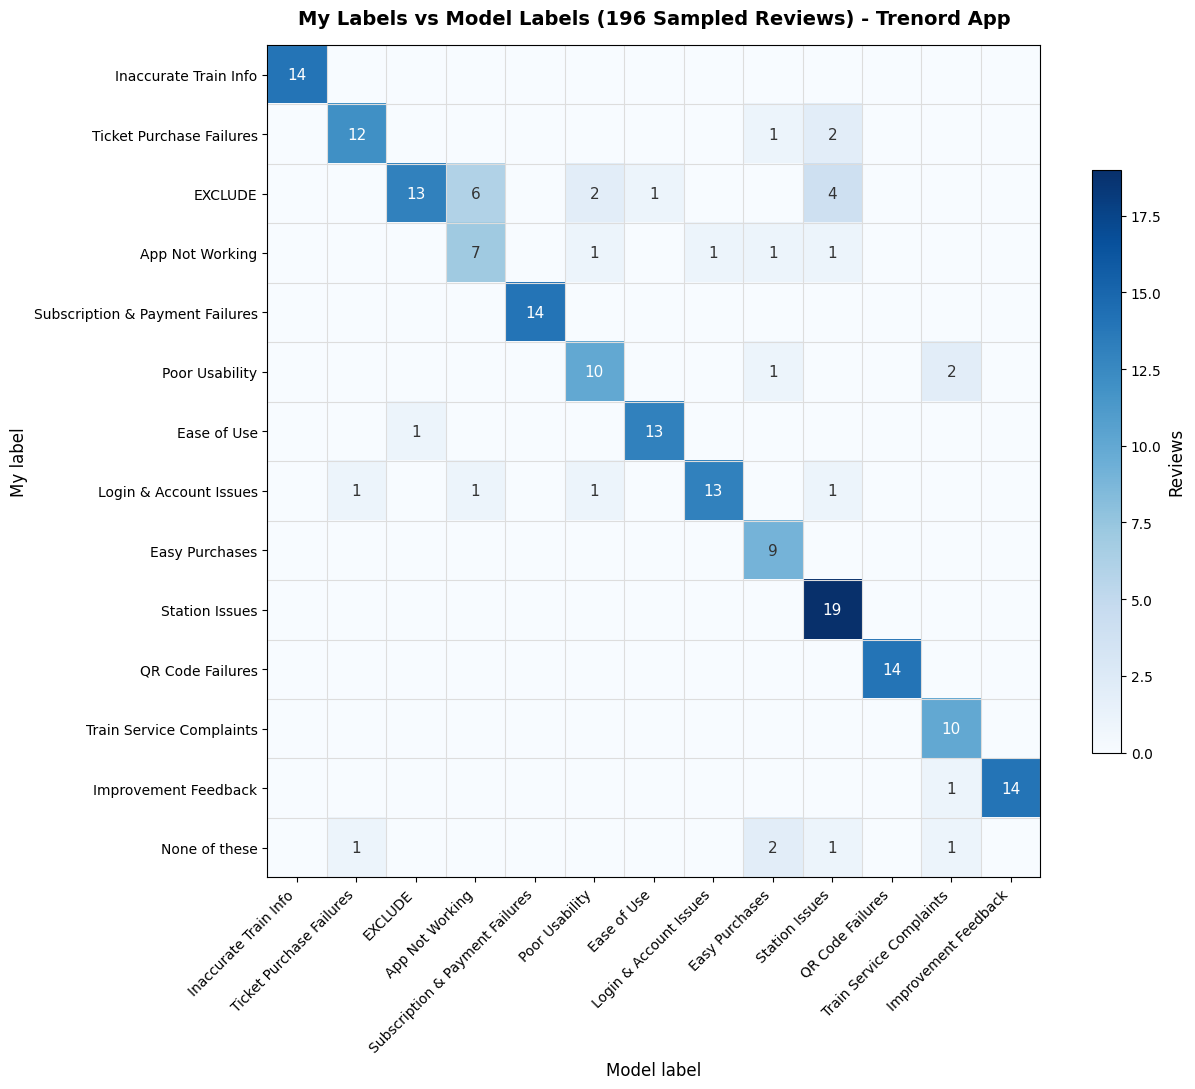

In [26]:
# --- CONFUSION MATRIX CHART ---
fig, ax = plt.subplots(figsize=(13, 11))

# A single hue, from white to dark blue: the darker the cell, the more reviews
image = ax.imshow(confusion_table.values, cmap="Blues", vmin=0)

# The count in each cell. Cells with 0 are left empty, so the disagreements stand out.
max_count = confusion_table.values.max()
for row_index in range(len(row_labels)):
    for column_index in range(len(column_labels)):
        count = confusion_table.iloc[row_index, column_index]
        if count == 0:
            continue
        # White on the dark cells, dark grey on the light ones, so every count can be read
        if count > max_count / 2:
            text_color = "white"
        else:
            text_color = "#333333"
        ax.text(column_index, row_index, str(count), ha="center", va="center", fontsize=11, color=text_color)

# Thin grey lines between the cells, so the empty ones can be followed along a row
ax.set_xticks(np.arange(len(column_labels) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(row_labels) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="#dddddd", linewidth=0.8)
ax.tick_params(which="minor", length=0)

ax.set_xticks(range(len(column_labels)))
ax.set_xticklabels(column_labels, rotation=45, ha="right", fontsize=10)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=10)

ax.set_title(f"My Labels vs Model Labels ({len(agreement_df)} Sampled Reviews) - Trenord App",
             fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Model label", fontsize=12)
ax.set_ylabel("My label", fontsize=12)

colorbar = fig.colorbar(image, ax=ax, shrink=0.7)
colorbar.set_label("Reviews", fontsize=12)

plt.tight_layout()
plt.savefig(CONFUSION_CHART_PATH, dpi=150)
plt.show()

In [27]:
# --- THE FIVE MOST FREQUENT DISAGREEMENTS ---
# Every cell off the diagonal with at least one review, in the order of the table
disagreement_pairs = []
for my_label in row_labels:
    for model_label in column_labels:
        count = confusion_table.loc[my_label, model_label]
        if my_label != model_label and count > 0:
            disagreement_pairs.append((my_label, model_label, int(count)))

# sorted() keeps the table order between pairs with the same count, so the result is the same on every run
disagreement_pairs = sorted(disagreement_pairs, key=lambda pair: pair[2], reverse=True)

n_disagreements = len(agreement_df) - n_agree
print(f"Disagreements: {n_disagreements}, in {len(disagreement_pairs)} different pairs of labels")
print(f"Disagreements where I chose EXCLUDE      : {int(confusion_table.loc['EXCLUDE'].sum() - confusion_table.loc['EXCLUDE', 'EXCLUDE'])}")
print(f"Disagreements where I chose None of these: {int(confusion_table.loc['None of these'].sum())}")
print()
print("My label → model label: reviews")
for my_label, model_label, count in disagreement_pairs[:5]:
    print(f"  {my_label} → {model_label}: {count}")

# The fifth count may be shared by pairs that are not shown
fifth_count = disagreement_pairs[4][2]
n_tied_not_shown = 0
for my_label, model_label, count in disagreement_pairs[5:]:
    if count == fifth_count:
        n_tied_not_shown += 1
print()
print(f"Pairs not shown with the same count as the fifth ({fifth_count}): {n_tied_not_shown}")

Disagreements: 34, in 22 different pairs of labels
Disagreements where I chose EXCLUDE      : 13
Disagreements where I chose None of these: 5

My label → model label: reviews
  EXCLUDE → App Not Working: 6
  EXCLUDE → Station Issues: 4
  Ticket Purchase Failures → Station Issues: 2
  EXCLUDE → Poor Usability: 2
  Poor Usability → Train Service Complaints: 2

Pairs not shown with the same count as the fifth (2): 1


### The disagreements file

To study the disagreements I need to read the reviews, so each one is written with its text to `labeling/validation_disagreements.csv`. The folder is gitignored, and nothing of the file is printed here.

In [28]:
# --- WRITE THE DISAGREEMENTS FOR MY STUDY ---
# The text comes from the coding sheet: the review as I read it while coding
disagreement_df = coding_df[["sample_id", "text"]].merge(agreement_df, on="sample_id", how="inner", validate="one_to_one")
disagreement_df = disagreement_df[disagreement_df["my_label"] != disagreement_df["model_label"]]
disagreement_df = disagreement_df[["sample_id", "text", "my_label", "model_label"]].sort_values("sample_id")

disagreement_df.to_csv(DISAGREEMENTS_PATH, index=False, encoding="utf-8-sig")

print(f"Rows written to labeling/validation_disagreements.csv: {len(disagreement_df)}")

Rows written to labeling/validation_disagreements.csv: 34


### Reading the agreement

Cohen's kappa is 0.812 (95% CI 0.763 to 0.862), just inside the "almost perfect" band (0.81 to 1.00) of Landis and Koch (1977), and the weighted agreement over all reviews is 86.6% (95% CI 81.7% to 91.2%), higher than the raw 82.7% (95% CI 78.1% to 87.2%) because the largest labels have a high precision. 13 of the 34 disagreements are reviews I coded EXCLUDE, most often against App Not Working (6, with only 7 of its 14 reviews confirmed) and Station Issues (4), so most disagreements are about the line between a generic verdict and a specific problem. There is one coder, me, who also wrote the labels and renamed them after seeing the disagreements, so this shows that the labels match how I read the reviews, not that another person would read them the same way. The intervals describe sampling uncertainty only, and with 14 reviews per stratum the precision of each label is rough.